# COU 07506 Digital Signal Processing
## Week 3 — Lab 1B: Convolution, Correlation and Difference Equations

| | |
|---|---|
| **Name** | MAIMUNA SHABANI HAJI |
| **Registration number** | 250242423358 |
| **Date** | 25 November 2026 |
| **Group** | 30 |
| **Lecturer** | Dr. Haji Fimbombaya |

**Group 30 members**

1. PAUL MASHAKA NYANDA
2. MAIMUNA SHABANI HAJI
3. ABDULKARIM MAKIWA SAID
4. SYLIVESTER M. MAGUHWA
5. ABRON JAMES MPIRA

## Pre-lab preparation
Handout §1.7–1.9 read. ✔

**(a) Convolve $x(n) = \{1, -1, 2\}$ with $h(n) = \{2, 1, 0, 1\}$ by hand.**
Length $= 3 + 4 - 1 = 6$, using $y(n) = \sum_k x(k)h(n-k)$:

| n | terms | y(n) |
|---|---|---|
| 0 | (1)(2) | 2 |
| 1 | (1)(1) + (−1)(2) | −1 |
| 2 | (1)(0) + (−1)(1) + (2)(2) | 3 |
| 3 | (1)(1) + (−1)(0) + (2)(1) | 3 |
| 4 | (−1)(1) + (2)(0) | −1 |
| 5 | (2)(1) | 2 |

$y(n) = \{2, -1, 3, 3, -1, 2\}$

**(b) Is $y(n) = n\,x(n)$ time-invariant?**
Test: delay the input by $k$ → the response is $y_1(n) = n\,x(n-k)$.
Delay the output by $k$ → $y(n-k) = (n-k)\,x(n-k)$.
Since $n\,x(n-k) \ne (n-k)\,x(n-k)$ in general, the system is **time-variant**. The gain $n$ depends on
absolute time, so the same input gives a different output when it arrives later.

## Standard imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display
plt.rcParams["figure.figsize"] = (9, 3.5)
import time

## Task 3.1 — Convolution from the definition

In [2]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

print(conv([1, 2, 3, 1], [1, 1, 1]))       # expect [1 3 6 6 4 1]
print(np.convolve([1, 2, 3, 1], [1, 1, 1]))

# Pre-lab answer (a)
print("pre-lab (a), conv       :", conv([1, -1, 2], [2, 1, 0, 1]))
print("pre-lab (a), np.convolve:", np.convolve([1, -1, 2], [2, 1, 0, 1]))

[1. 3. 6. 6. 4. 1.]
[1 3 6 6 4 1]
pre-lab (a), conv       : [ 2. -1.  3.  3. -1.  2.]
pre-lab (a), np.convolve: [ 2 -1  3  3 -1  2]


In [3]:
rng = np.random.default_rng(0)
a, b = rng.standard_normal(2000), rng.standard_normal(2000)

t0 = time.perf_counter(); y_loop = conv(a, b); t_loop = time.perf_counter() - t0
t0 = time.perf_counter(); y_np = np.convolve(a, b); t_np = time.perf_counter() - t0
print(f"same result: {np.allclose(y_loop, y_np)}")
print(f"conv (Python loops): {t_loop*1e3:9.2f} ms")
print(f"np.convolve        : {t_np*1e3:9.3f} ms")
print(f"np.convolve is about {t_loop/t_np:,.0f} times faster")

same result: True
conv (Python loops):   1680.58 ms
np.convolve        :     0.525 ms
np.convolve is about 3,199 times faster


## Task 3.2 — Smoothing a noisy signal by convolution
$x(n) = \sin(2\pi n/50) + 0.5\,w(n)$ for $0 \le n < 300$, smoothed with moving-average filters of length $M$ = 3, 9 and 25.

  M   RMS error vs clean  peak of output
  -                0.509   (noisy input)
  3                0.290           1.289
  9                0.152           1.105
 25                0.277           0.744


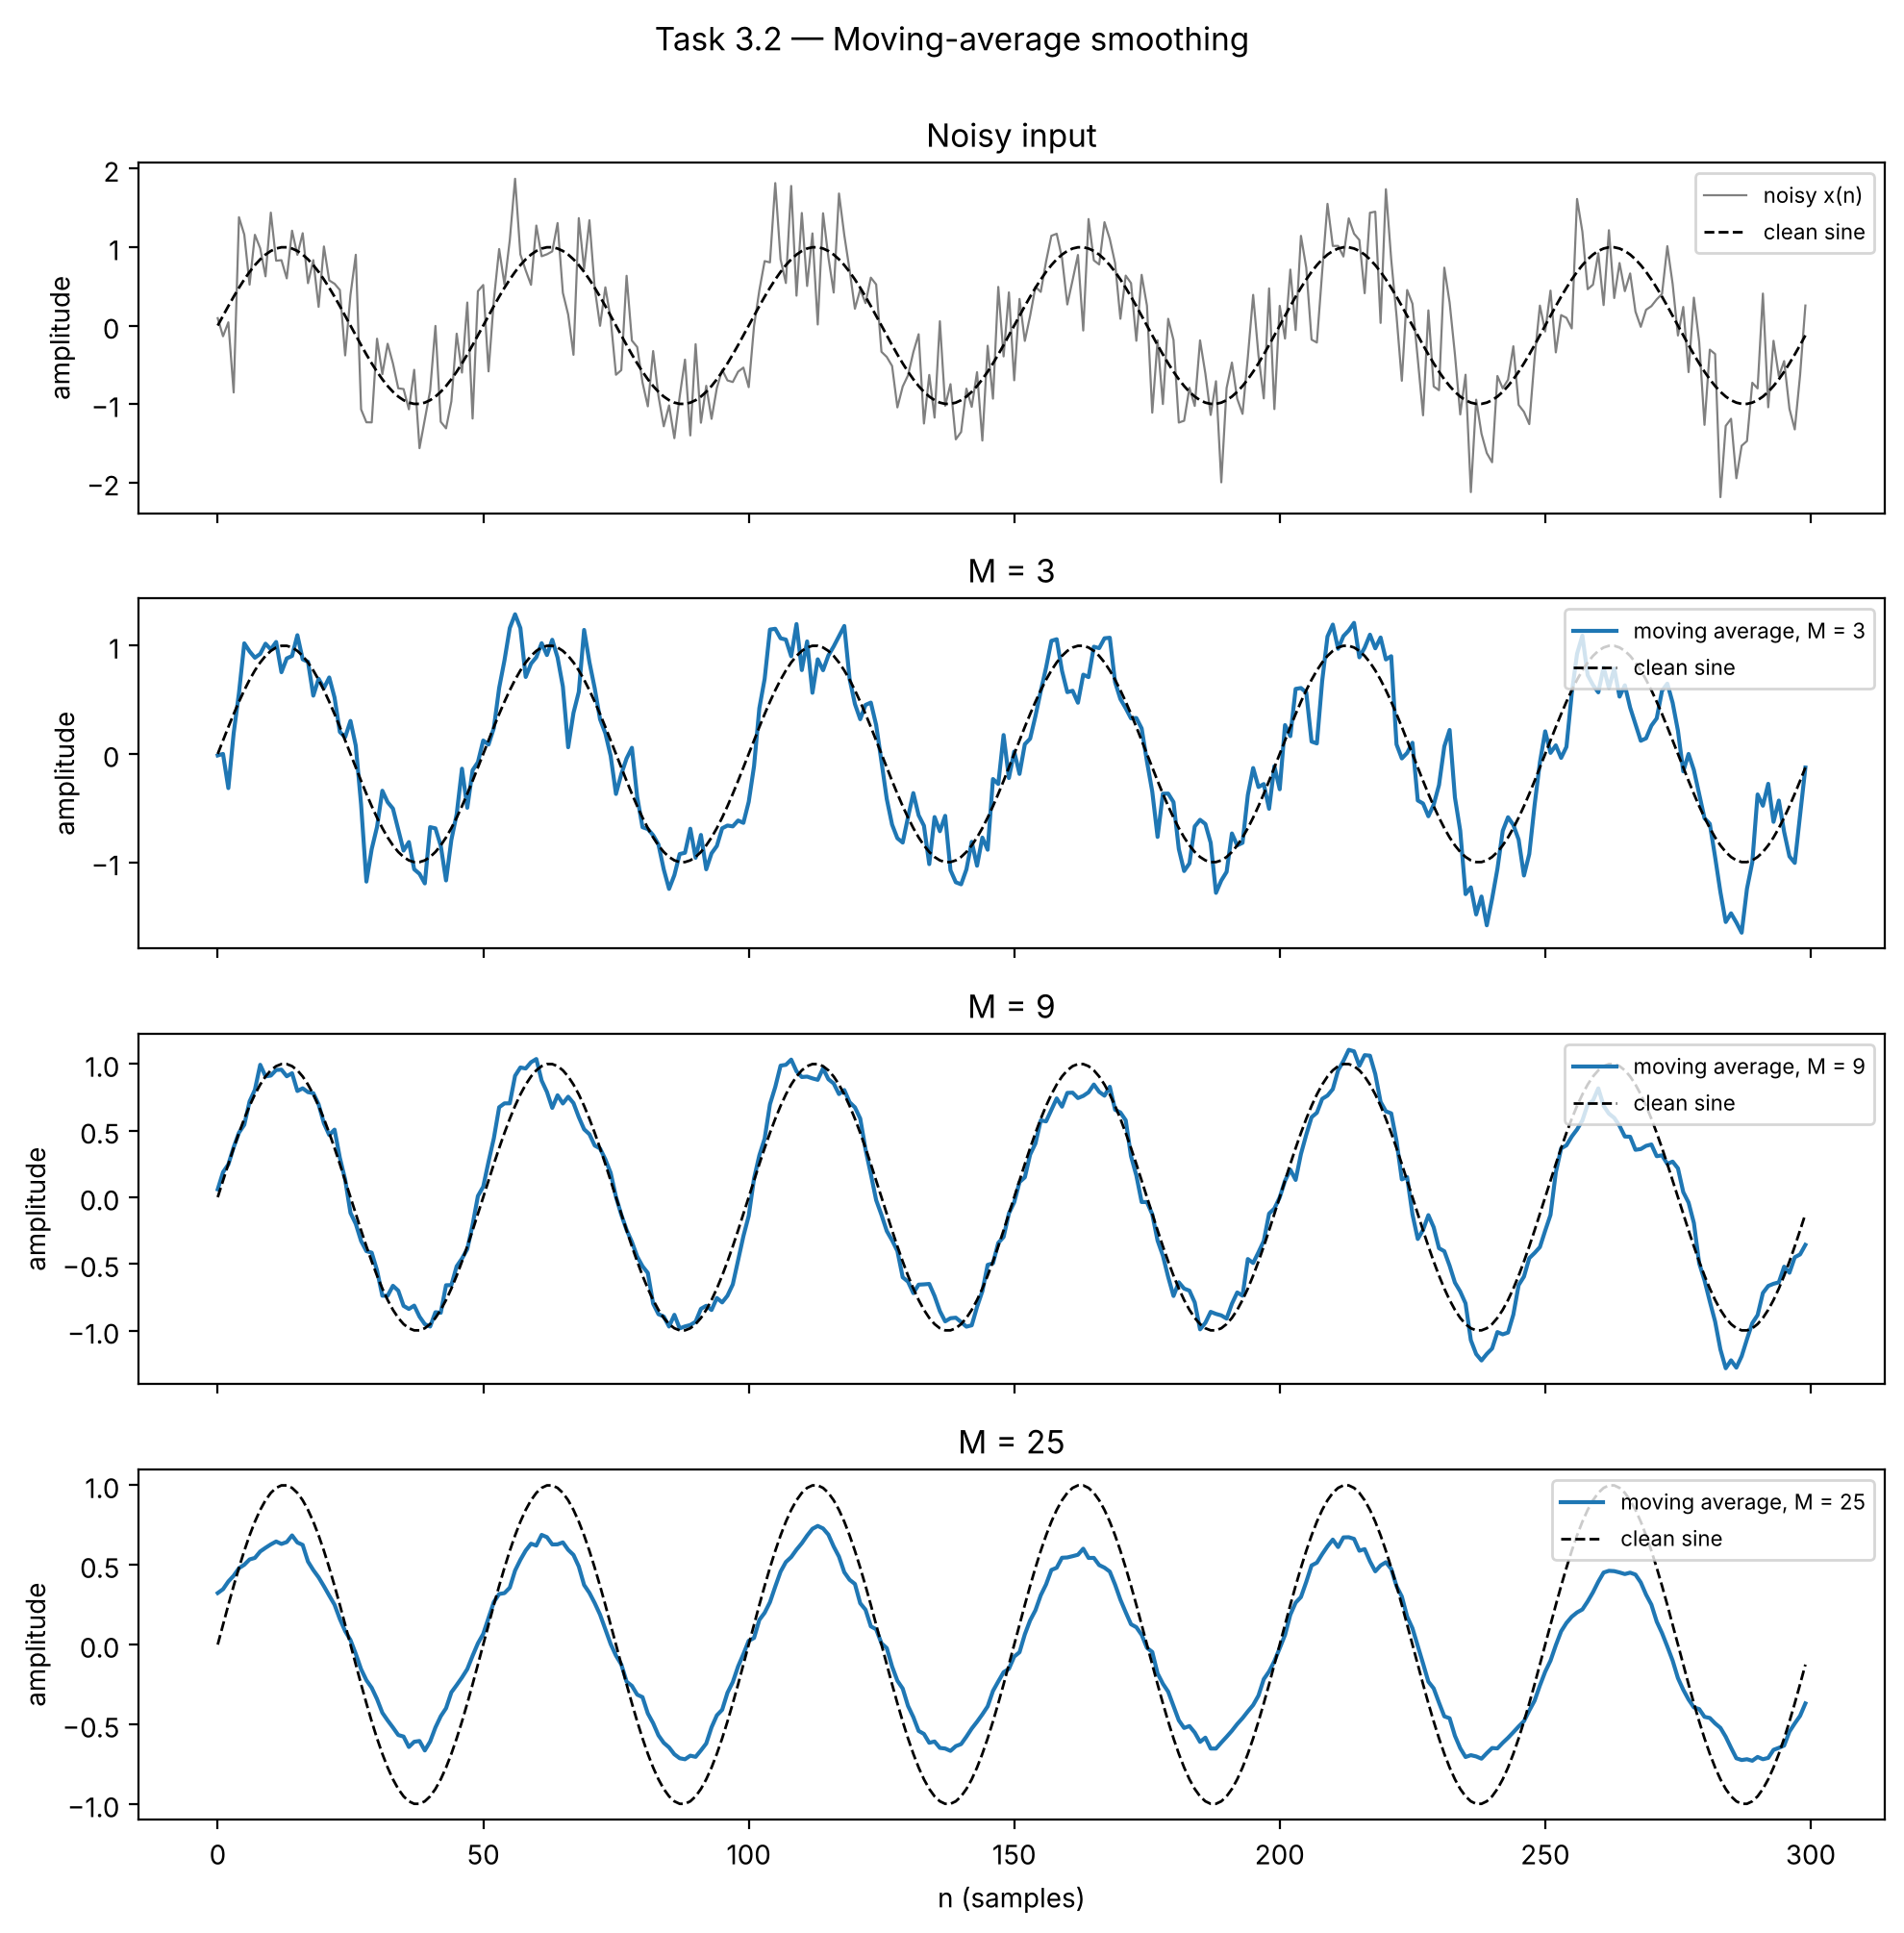

In [4]:
rng = np.random.default_rng(2)
n = np.arange(300)
clean = np.sin(2*np.pi*n/50)
x = clean + 0.5*rng.standard_normal(300)

fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
axes[0].plot(n, x, color="grey", lw=0.8, label="noisy x(n)")
axes[0].plot(n, clean, "k--", lw=1, label="clean sine")
axes[0].set_title("Noisy input")
print(f"{'M':>3} {'RMS error vs clean':>20} {'peak of output':>15}")
print(f"{'-':>3} {np.sqrt(np.mean((x-clean)**2)):20.3f} {'(noisy input)':>15}")
for ax, M in zip(axes[1:], [3, 9, 25]):
    h = np.ones(M)/M
    y = np.convolve(x, h, mode="same")
    ax.plot(n, y, label=f"moving average, M = {M}")
    ax.plot(n, clean, "k--", lw=1, label="clean sine")
    ax.set_title(f"M = {M}")
    inner = slice(25, 275)                       # ignore the edges
    print(f"{M:3d} {np.sqrt(np.mean((y-clean)[inner]**2)):20.3f} {np.max(y[inner]):15.3f}")
for ax in axes:
    ax.set_ylabel("amplitude"); ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("n (samples)")
fig.suptitle("Task 3.2 — Moving-average smoothing", y=1.0)
plt.tight_layout(); plt.show()

**Trade-off.** A longer filter averages more noise samples, so the noise falls by about $1/\sqrt{M}$. It also
averages a larger part of the sine wave itself.
- $M = 3$ removes only a little noise.
- $M = 9$ gives a clean sine with almost the right amplitude.
- $M = 25$ is half a period of the sine (50 samples). It is very smooth, but the peaks are clearly reduced:
  the theoretical gain at this frequency is $\sin(\pi M/50)/(M\sin(\pi/50)) \approx 0.64$, and the plot
  peaks at about 0.6–0.7. Positive and negative halves of the sine are averaged together, so its RMS error is
  actually *worse* than $M = 9$.

More smoothing means less noise but more **distortion** (loss of amplitude and sharpness) of the wanted
signal. The best $M$ is the largest one that is still short compared with the period of the signal. The
edges are also distorted, because `mode="same"` pads with zeros there.

## Task 3.3 — Testing linearity and time-invariance numerically

In [5]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0
systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}
for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]           # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]        # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear} time-invariant={tinv}")

x^2             linear=False time-invariant=True
n x(n)          linear=True time-invariant=False
moving average  linear=True time-invariant=True


**Explanation (handout §1.7)**
- **$y = x^2$: non-linear, time-invariant.** $(ax_1 + bx_2)^2 = a^2x_1^2 + 2abx_1x_2 + b^2x_2^2 \ne ax_1^2 + bx_2^2$,
  so superposition fails. The operation is the same at every $n$, so a delayed input gives a delayed output.
- **$y = n\,x(n)$: linear, time-variant.** Multiplying by $n$ respects superposition,
  $n(ax_1+bx_2) = a\,nx_1 + b\,nx_2$. However, the gain $n$ changes with time (pre-lab (b)), so shifting the input does not just
  shift the output.
- **Moving average: linear and time-invariant (LTI).** It is a convolution with a fixed $h(n)$, and every
  convolution is LTI.

## Task 3.4 — Finding a hidden delay with cross-correlation

estimated delay: 37 samples


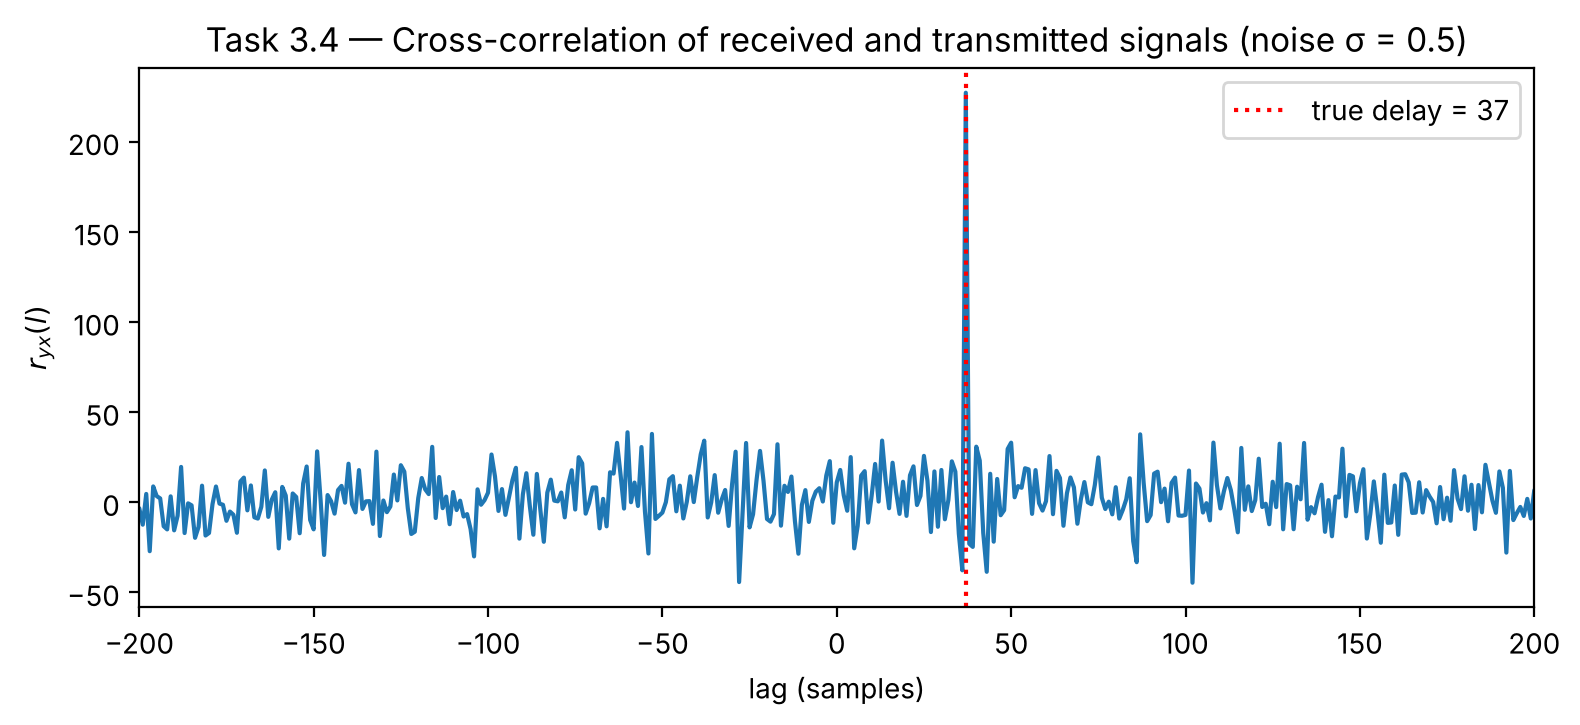

In [6]:
rng = np.random.default_rng(1)
fs = 1000
x = rng.standard_normal(500)                  # transmitted signal
true_delay = 37
y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + 0.5*rng.standard_normal(500)
r = signal.correlate(y, x, mode="full")
lags = signal.correlation_lags(len(y), len(x), mode="full")
print("estimated delay:", lags[np.argmax(r)], "samples")
plt.plot(lags, r); plt.xlim(-200, 200)
plt.xlabel("lag (samples)"); plt.ylabel("$r_{yx}(l)$")
plt.title("Task 3.4 — Cross-correlation of received and transmitted signals (noise σ = 0.5)")
plt.axvline(true_delay, color="r", ls=":", label=f"true delay = {true_delay}"); plt.legend(); plt.show()

**Increasing the noise.** First one run per noise level (like the code above), then 200 random runs per level to measure how often the estimate is correct.

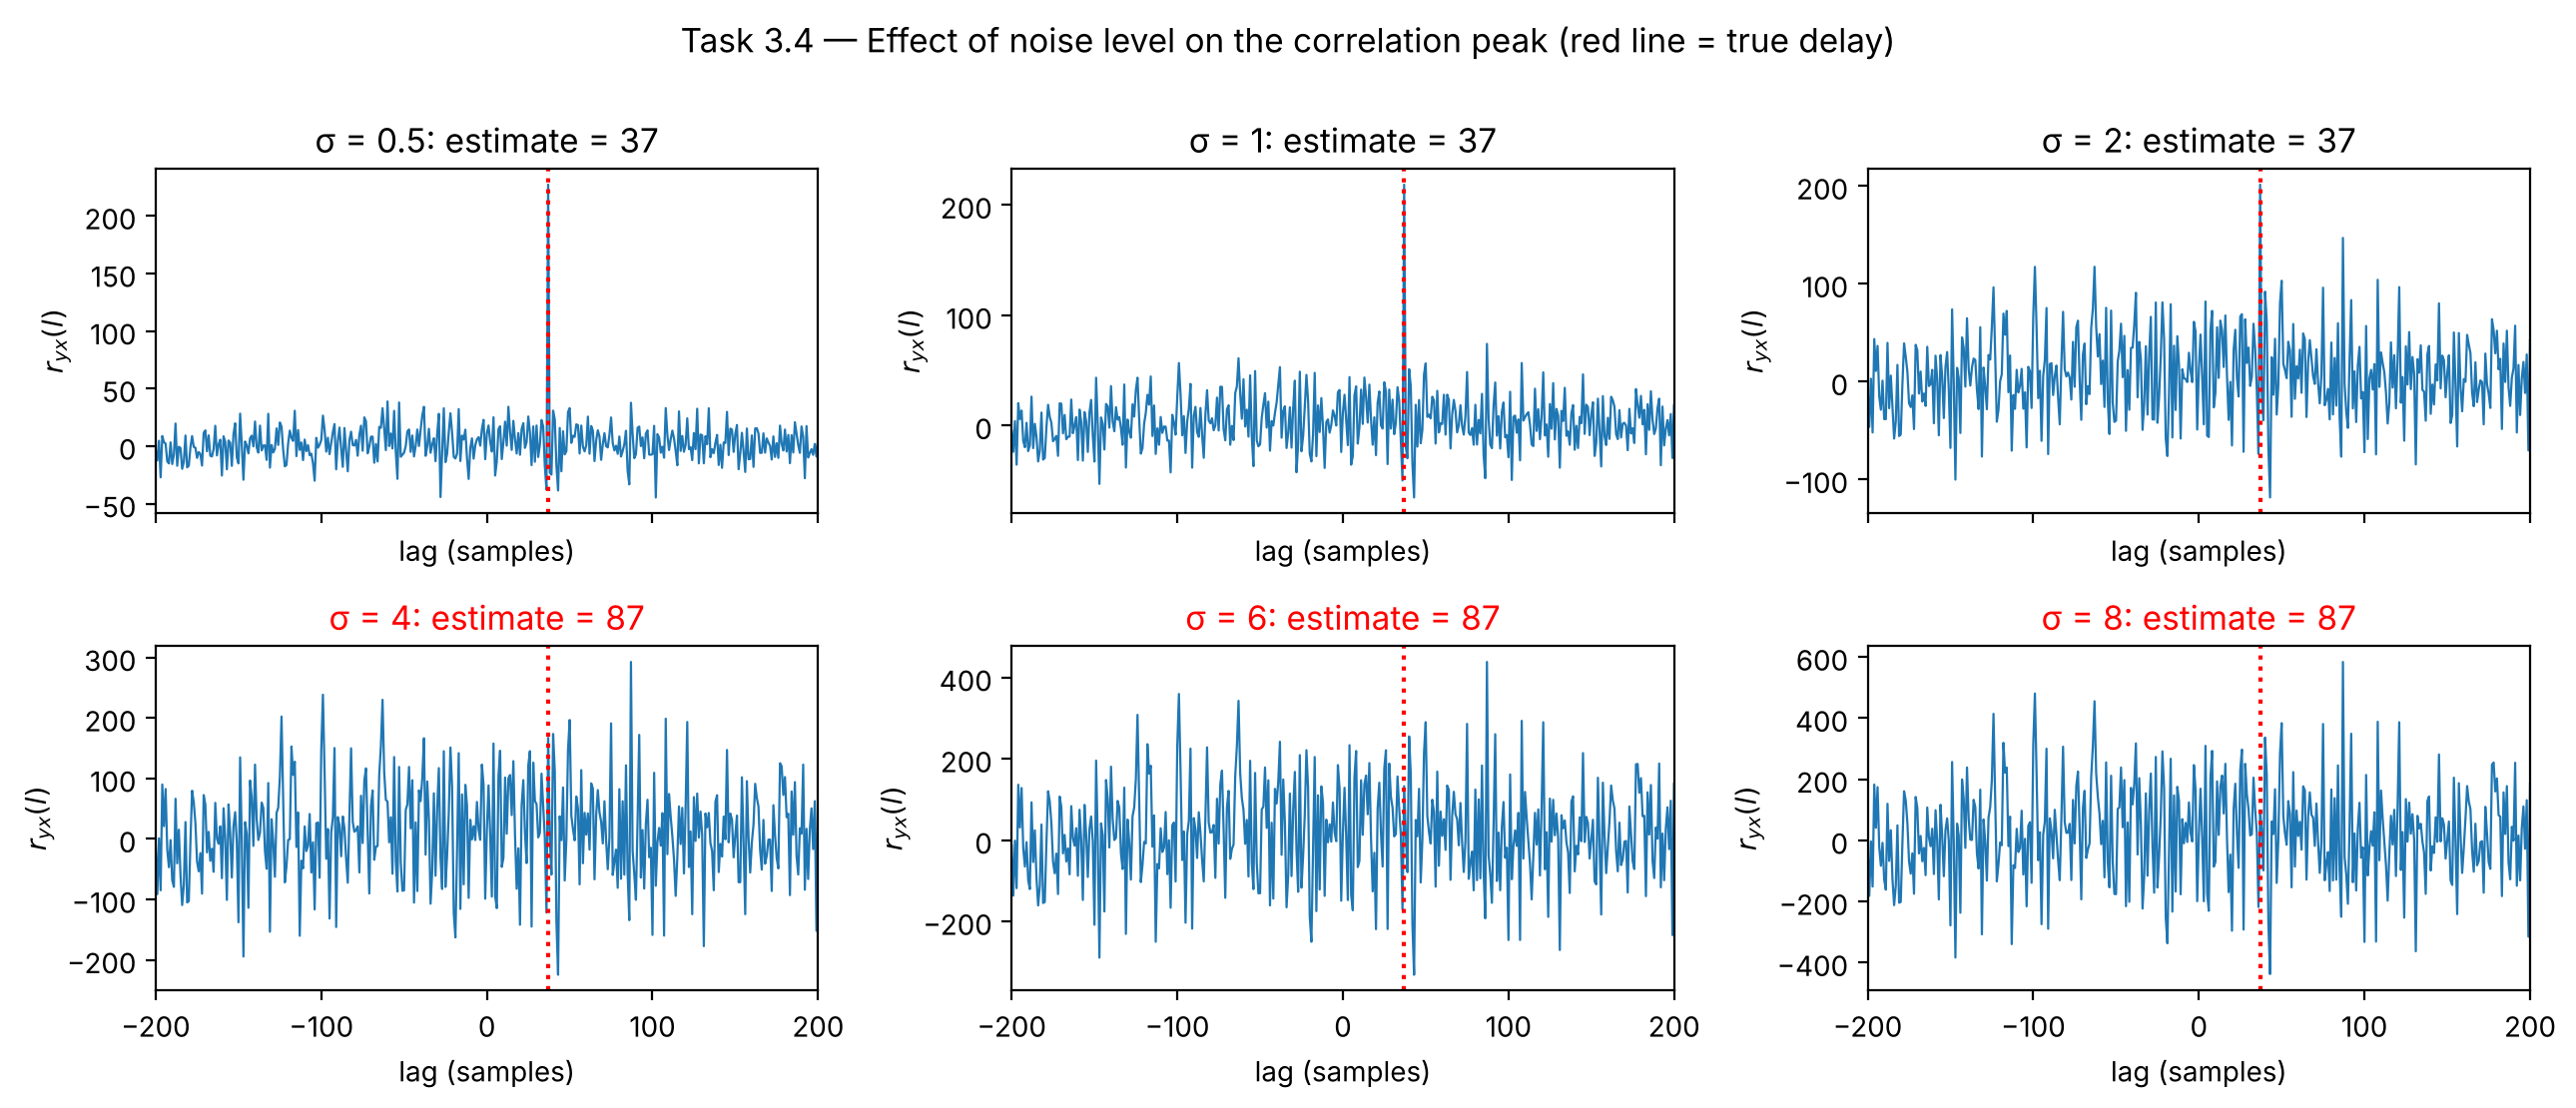

 sigma  SNR (dB)   correct estimates (200 runs)
   0.5       1.6                        100.0 %
     1      -4.4                        100.0 %
     2     -10.5                        100.0 %
     4     -16.5                         66.5 %
     6     -20.0                         27.5 %
     8     -22.5                         12.5 %


In [7]:
def estimate_delay(sigma, rng, N=500, d=37, gain=0.6):
    x = rng.standard_normal(N)
    y = np.concatenate([np.zeros(d), gain*x])[:N] + sigma*rng.standard_normal(N)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(N, N, mode="full")
    return lags[np.argmax(r)], lags, r

sigmas = [0.5, 1, 2, 4, 6, 8]
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for ax, s in zip(axes.flat, sigmas):
    est, lags, r = estimate_delay(s, np.random.default_rng(1))
    ax.plot(lags, r, lw=0.8); ax.set_xlim(-200, 200)
    ax.axvline(37, color="r", ls=":")
    ax.set_title(f"σ = {s}: estimate = {est}", color="k" if est == 37 else "r")
    ax.set_xlabel("lag (samples)"); ax.set_ylabel("$r_{yx}(l)$")
fig.suptitle("Task 3.4 — Effect of noise level on the correlation peak (red line = true delay)", y=1.0)
plt.tight_layout(); plt.show()

rng = np.random.default_rng(123)
print(f"{'sigma':>6} {'SNR (dB)':>9} {'correct estimates (200 runs)':>30}")
for s in sigmas:
    ok = sum(estimate_delay(s, rng)[0] == 37 for _ in range(200))
    print(f"{s:6g} {10*np.log10(0.36/s**2):9.1f} {ok/2:28.1f} %")

In [8]:
c = 343.0                              # speed of sound (m/s)
d_samples = 37
tau = d_samples / fs
print(f"delay = {d_samples} samples / {fs} Hz = {tau*1e3:.0f} ms")
print(f"distance travelled = c * tau = {c} * {tau} = {c*tau:.2f} m")
print(f"(for an echo that goes there and back, the reflector is {c*tau/2:.2f} m away)")

delay = 37 samples / 1000 Hz = 37 ms
distance travelled = c * tau = 343.0 * 0.037 = 12.69 m
(for an echo that goes there and back, the reflector is 6.35 m away)


**At what level does the estimate fail?** At σ = 0.5, 1 and 2 the peak is clear and the estimate is always 37.
At **σ = 4** (received signal about 16 dB below the noise) it **fails**: with the manual's random seed the
largest peak is a noise peak at lag 87, and over 200 random runs the estimate is correct only about two-thirds
of the time. At σ = 6 and 8 the noise peaks are usually higher than the true peak, and the estimate is mostly
wrong. The breakdown point is therefore between σ = 2 and σ = 4. Correlation works far below 0 dB SNR because it
sums over 500 samples. The peak grows with $N$, while the noise in $r(l)$ only grows with $\sqrt{N}$.

**Distance:** 37 samples at $f_s$ = 1000 Hz is 37 ms. At 343 m/s the sound travels **12.7 m** (or the
reflector is 6.3 m away if this is a round-trip echo).

## Task 3.5 — Difference equation
$y(n) - \tfrac{3}{4}y(n-1) + \tfrac{1}{8}y(n-2) = x(n) + x(n-1)$, so $b = [1, 1]$ and $a = [1, -0.75, 0.125]$.

 n  recursion    lfilter  closed form
 0    1.00000    1.00000      1.00000
 1    1.75000    1.75000      1.75000
 2    1.18750    1.18750      1.18750
 3    0.67188    0.67188      0.67188
 4    0.35547    0.35547      0.35547
 5    0.18262    0.18262      0.18262
 6    0.09253    0.09253      0.09253
 7    0.04657    0.04657      0.04657
 8    0.02336    0.02336      0.02336
 9    0.01170    0.01170      0.01170
all three agree: True


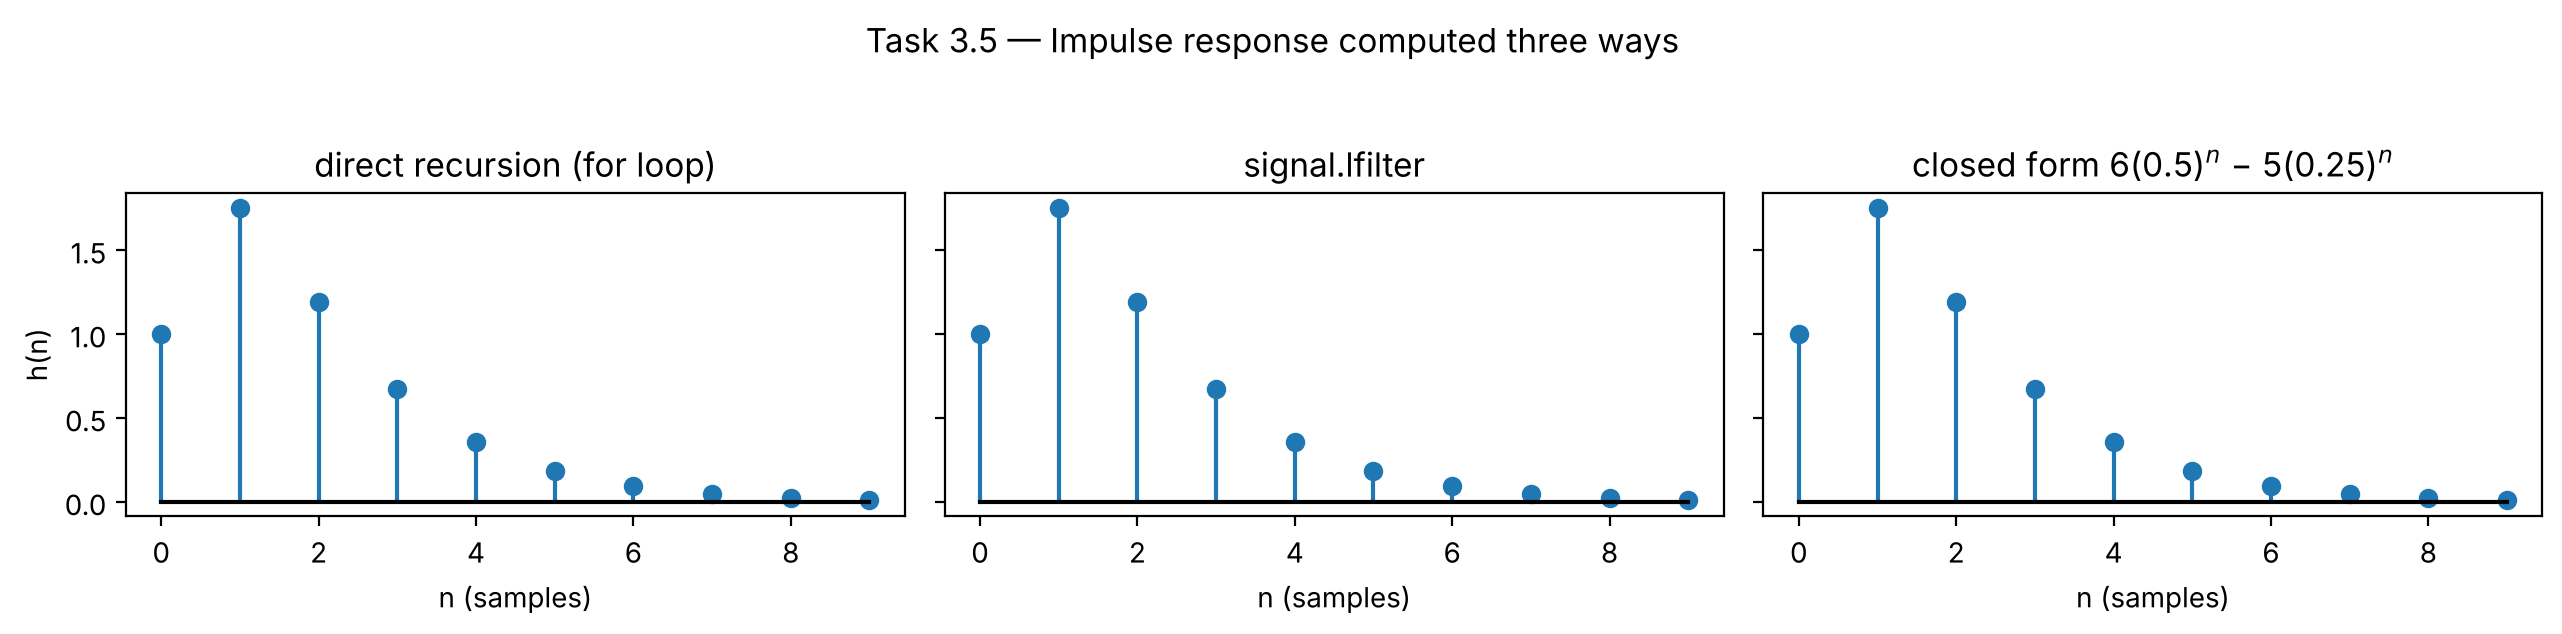

In [9]:
N = 10
n = np.arange(N)
impulse = np.zeros(N); impulse[0] = 1

# 1. direct recursion: y(n) = x(n) + x(n-1) + 0.75 y(n-1) - 0.125 y(n-2)
h_loop = np.zeros(N)
for k in range(N):
    xk = impulse[k]
    xk1 = impulse[k-1] if k >= 1 else 0.0
    yk1 = h_loop[k-1] if k >= 1 else 0.0
    yk2 = h_loop[k-2] if k >= 2 else 0.0
    h_loop[k] = xk + xk1 + 0.75*yk1 - 0.125*yk2

# 2. lfilter
h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

# 3. closed form (handout Example 2.5)
h_cf = 6*0.5**n - 5*0.25**n

print(f"{'n':>2} {'recursion':>10} {'lfilter':>10} {'closed form':>12}")
for k in n:
    print(f"{k:2d} {h_loop[k]:10.5f} {h_lf[k]:10.5f} {h_cf[k]:12.5f}")
print("all three agree:", np.allclose(h_loop, h_lf) and np.allclose(h_lf, h_cf))

fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, h, title in zip(axes, [h_loop, h_lf, h_cf],
                        ["direct recursion (for loop)", "signal.lfilter", "closed form 6(0.5)$^n$ − 5(0.25)$^n$"]):
    ax.stem(n, h, basefmt="k-"); ax.set_title(title); ax.set_xlabel("n (samples)")
axes[0].set_ylabel("h(n)")
fig.suptitle("Task 3.5 — Impulse response computed three ways", y=1.04)
plt.tight_layout(); plt.show()

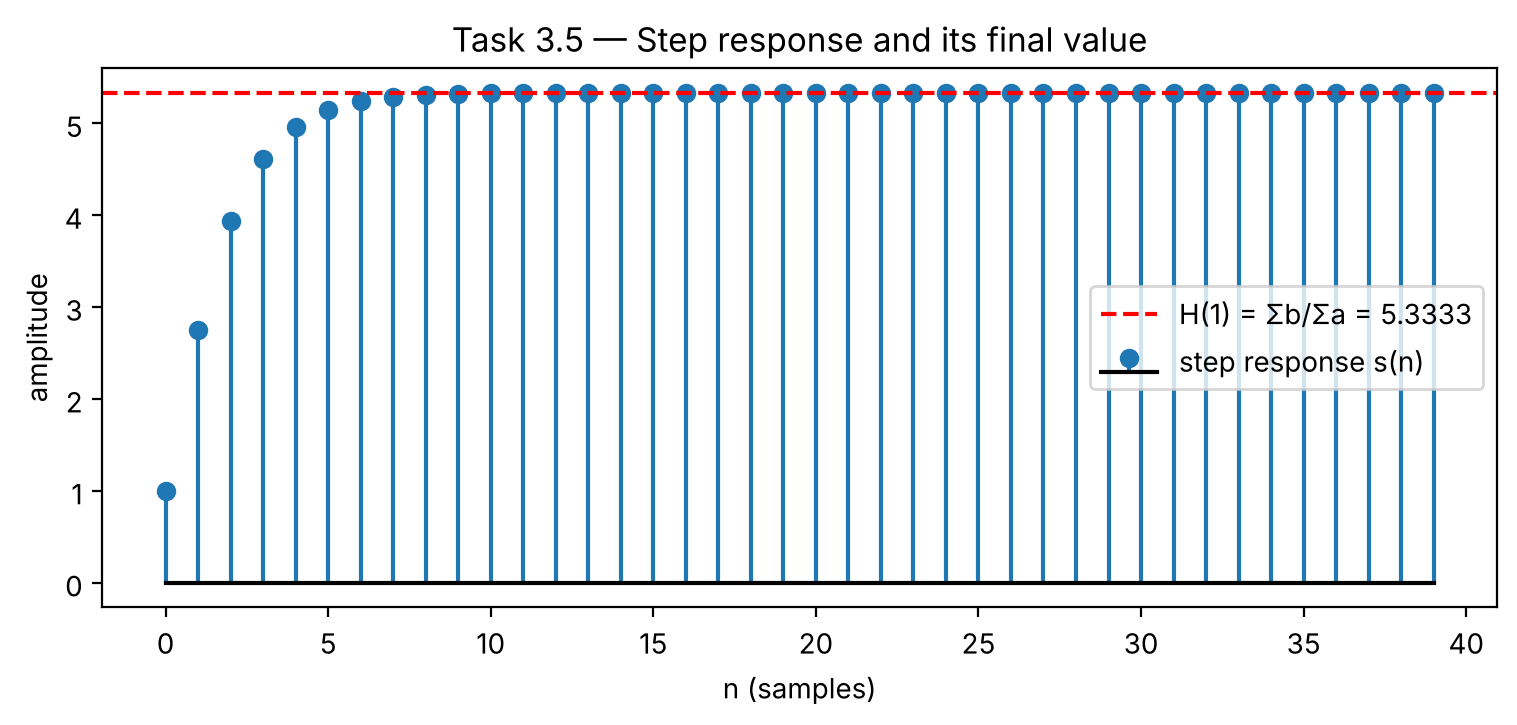

final value of step response s(39) = 5.333333
H(1) = (1+1)/(1-0.75+0.125) = 2/0.375 = 5.333333


In [10]:
n = np.arange(40)
s = signal.lfilter([1, 1], [1, -0.75, 0.125], np.ones(40))
H1 = np.sum([1, 1]) / np.sum([1, -0.75, 0.125])
plt.stem(n, s, basefmt="k-", label="step response s(n)")
plt.axhline(H1, color="r", ls="--", label=f"H(1) = Σb/Σa = {H1:.4f}")
plt.xlabel("n (samples)"); plt.ylabel("amplitude"); plt.legend()
plt.title("Task 3.5 — Step response and its final value"); plt.show()
print(f"final value of step response s(39) = {s[-1]:.6f}")
print(f"H(1) = (1+1)/(1-0.75+0.125) = 2/0.375 = {H1:.6f}")

The step response settles at 5.3333, exactly $H(1) = \sum b/\sum a = 2/0.375$. A constant input is the frequency
$\omega = 0$ ($z = 1$), so its steady-state gain is $H(z)$ evaluated at $z = 1$.

**Checkpoint 3:** the output of Task 3.3 and the three matching impulse responses of Task 3.5 are shown above.

## Analysis questions
**1. Why is `np.convolve` so much faster than my double loop? Number of multiplications for lengths L and M?**
Direct convolution needs $L \times M$ multiplications in both cases. For $L = M = 2000$ that is 4 million, and the
loop also checks the index condition $(L+M-1)\cdot L \approx 8$ million times. In my function each operation is
executed by the Python interpreter one at a time, with type checking and object handling for every step.
`np.convolve` performs the same arithmetic in compiled C code on contiguous arrays, with no per-element
interpreter overhead and with CPU vector instructions. The measured speed-up in Task 3.1 is several thousand
times. For very long signals an FFT-based method (Week 5) reduces the operation count itself, to about
$N\log_2 N$.

**2. Which of the three systems in Task 3.3 are LTI? Could I have predicted this without running code?**
Only the **moving average** is LTI. Yes, it can be predicted from the definitions: a squarer is non-linear
(squaring a sum creates cross terms), and a gain that depends on $n$ makes a system time-variant. Any system
that can be written as a convolution with a fixed $h(n)$ is LTI.

**3. Two engineering applications of cross-correlation in Tanzania.**
- **Water-pipe leak detection** (e.g. DAWASA in Dar es Salaam): two sensors on a pipe record the leak noise. The
  lag of the cross-correlation peak gives the arrival-time difference, and from the sound speed in the pipe
  the position of the leak can be found without digging up the road.
- **GPS / navigation and mobile networks:** a GPS receiver (in boda-boda tracking or ride-hailing apps)
  correlates the received signal with each satellite's known code. The peak lag gives the travel time, and so
  the distance to each satellite. Mobile networks (Vodacom, Airtel, Yas) use correlation in the same way to
  synchronise phones with the base station.
- *(also:* airport radar at JNIA finds the distance to an aircraft from the delay of the echo.)

**4. Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.**
It is **IIR**. The output depends on past outputs ($a_1, a_2 \ne 0$), and $h(n) = 6(0.5)^n - 5(0.25)^n$ is
non-zero for every $n \ge 0$ (it never becomes exactly zero). It is **stable**. Both terms decay
geometrically because $|0.5| < 1$ and $|0.25| < 1$ (these are the poles), so
$\sum|h(n)| \le 6/(1-0.5) + 5/(1-0.25) = 18.7 < \infty$. The plots show $h(n)$ dying out, and the step response
settling to a finite value.

## Deliverables
`COU07506_Week03_250242423358.ipynb` with Tasks 3.1–3.5, the timing comparison, the plots, the answers and the
AI-use statement.

## AI-use statement
**Tool used:** Claude (Anthropic), a generative-AI assistant.

**What it was used for:** suggesting and explaining code for the tasks in this notebook and drafting
explanations, which I then reviewed and rewrote in my own words.

**How the results were checked:** the convolution function was checked against the given answer [1 3 6 6 4 1], my hand calculation and np.convolve; the delay estimator was tested with a known delay of 37 samples; the three impulse responses were compared with np.allclose and the step-response final value with H(1).

I have run the notebook from top to bottom (Restart kernel → Run all) and I can explain every line of the code.